In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

X = np.load("../results/X.npy")
Y = np.load("../results/Y.npy")

print(X.shape)
print(Y.shape)

(600, 87)
(600,)


In [2]:
neuron_counts = X[:, 0]

values, counts = np.unique(neuron_counts, return_counts=True)

print(values)
print(counts)

directions = np.unique(Y)
print(directions)

[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 48 50 51 52
 55 59 61]
[349  68  25  18  10   5  10   5   5   9   6   4   1   4   4   3   2   1
   2   6   4   4   1   2   2   1   6   2   2   4   3   1   2   2   1   1
   3   1   1   3   1   1   2   2   3   2   2   1   1   1   1]
[  0.  45.  90. 135. 180. 225. 270. 315.]


In [3]:
val_90 = neuron_counts[Y == 90]

print(val_90.shape)

val_90_mean = sum(val_90) / 75
print(val_90_mean)

(75,)
0.26666666666666666


In [4]:
mean_counts = []

for i in range(len(directions)):
    neur_val = neuron_counts[Y == directions[i]]
    neur_val_mean = sum(neur_val) / len(neur_val)
    mean_counts.append(neur_val_mean)

print(mean_counts)

[np.float64(21.946666666666665), np.float64(0.5733333333333334), np.float64(0.26666666666666666), np.float64(0.32), np.float64(16.026666666666667), np.float64(0.36), np.float64(0.24), np.float64(1.3866666666666667)]


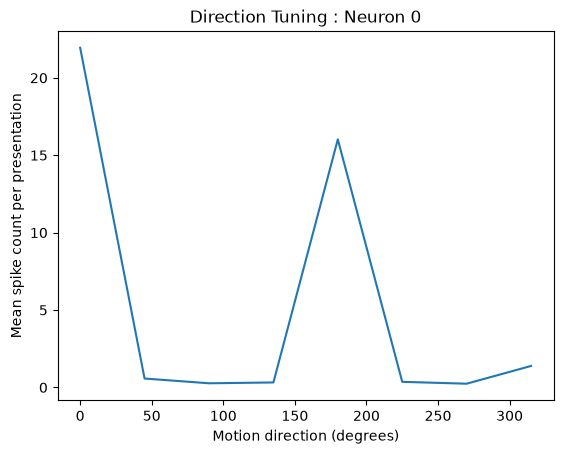

In [5]:
plt.plot(directions, mean_counts)
plt.title("Direction Tuning : Neuron 0")
plt.xlabel("Motion direction (degrees)")
plt.ylabel("Mean spike count per presentation")
plt.show()

In [6]:
val_0 = neuron_counts[Y == 0]
val_0_mean = np.mean(val_0)
val_0_std = np.std(val_0)

val_180 = neuron_counts[Y == 180]
val_180_mean = np.mean(val_180)
val_180_std = np.std(val_180)

print(val_0_mean, val_0_std)
print(val_180_mean, val_180_std)

21.946666666666665 16.745063617542797
16.026666666666667 13.230241452403236


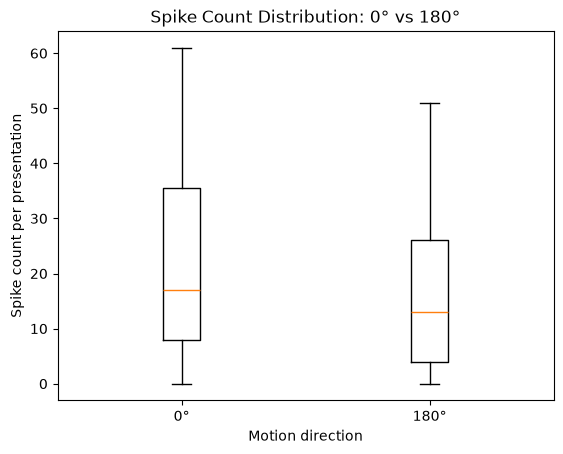

In [7]:
plt.boxplot([val_0, val_180])
plt.xticks([1, 2], ["0°", "180°"])
plt.title("Spike Count Distribution: 0° vs 180°")
plt.xlabel("Motion direction")
plt.ylabel("Spike count per presentation")
plt.show()

In [8]:
DSI_neur0 = (val_0_mean - val_180_mean) / (val_0_mean + val_180_mean)

print(DSI_neur0)

0.15589887640449435


In [9]:
temporal_frequencies = np.load("../results/temporal_frequencies.npy")

print(temporal_frequencies.shape)
print(np.unique(temporal_frequencies))

(600,)
[ 1.  2.  4.  8. 15.]


In [10]:
for direction in [0, 180]:
    frequencies = temporal_frequencies[Y == direction]

    values, counts = np.unique(frequencies, return_counts=True)

    print("Direction:", direction)
    print(np.column_stack((values, counts)))

Direction: 0
[[ 1. 15.]
 [ 2. 15.]
 [ 4. 15.]
 [ 8. 15.]
 [15. 15.]]
Direction: 180
[[ 1. 15.]
 [ 2. 15.]
 [ 4. 15.]
 [ 8. 15.]
 [15. 15.]]


In [11]:
for frequency in np.unique(temporal_frequencies):
    print("Temporal frequency:", frequency)

    for direction in [0, 180]:
        mask = (Y == direction) & (temporal_frequencies == frequency)

        responses = neuron_counts[mask]

        print(
            "Direction:", direction,
            "Trials:", len(responses),
            "Mean:", np.mean(responses) if len(responses) > 0 else np.nan
        )

Temporal frequency: 1.0
Direction: 0 Trials: 15 Mean: 37.06666666666667
Direction: 180 Trials: 15 Mean: 26.8
Temporal frequency: 2.0
Direction: 0 Trials: 15 Mean: 24.6
Direction: 180 Trials: 15 Mean: 16.266666666666666
Temporal frequency: 4.0
Direction: 0 Trials: 15 Mean: 18.6
Direction: 180 Trials: 15 Mean: 16.666666666666668
Temporal frequency: 8.0
Direction: 0 Trials: 15 Mean: 18.066666666666666
Direction: 180 Trials: 15 Mean: 14.0
Temporal frequency: 15.0
Direction: 0 Trials: 15 Mean: 11.4
Direction: 180 Trials: 15 Mean: 6.4


In [12]:
stimulus_block = np.load("../results/stimulus_block.npy")
stimulus_block.shape
print(np.unique(stimulus_block))

[2. 5. 7.]


In [13]:
for sti_blo in np.unique(stimulus_block):
    print("Stimulus block:", sti_blo)
    for direction in [0, 180]:
        mask = (Y == direction) & (stimulus_block == sti_blo)

        responses = neuron_counts[mask]

        print(
            "Direction:", direction,
            "Trials:", len(responses),
            "Mean:", np.mean(responses) if len(responses) > 0 else np.nan
        )

Stimulus block: 2.0
Direction: 0 Trials: 15 Mean: 16.066666666666666
Direction: 180 Trials: 25 Mean: 8.92
Stimulus block: 5.0
Direction: 0 Trials: 30 Mean: 13.3
Direction: 180 Trials: 20 Mean: 8.1
Stimulus block: 7.0
Direction: 0 Trials: 30 Mean: 33.53333333333333
Direction: 180 Trials: 30 Mean: 27.233333333333334


In [14]:
print(pd.DataFrame(X))

     0   1   2   3   4    5   6   7   8   9   ...  77  78  79  80  81  82  83  \
0     1   7  22  43   1  315   7  69  45  82  ...  51   1   3   7   0   0   1   
1    19  50  33  21  28  147   7  21  18  44  ...  85   0   0   1   2   0   2   
2     0  19  36  12   0  231   3  49  43  91  ...  97   0   1   9   0   0   2   
3     1  11  44   1  15  110   0  13  18  39  ...  30   6   1   0   0   0   0   
4    11   3  32  39  38  114   3  70  27  76  ...  80  17   1   0  13   0   2   
..   ..  ..  ..  ..  ..  ...  ..  ..  ..  ..  ...  ..  ..  ..  ..  ..  ..  ..   
595   0  34  19   8  85   18   3   5  11  35  ...  84   0   0   0   0   0   0   
596   1  35  20  18  41   43   5   2  16  46  ...  74   0   0   0   0   0   0   
597   1   5  17  43   0  121  30  32  22  49  ...  77   2  12   0   2   0   0   
598   0  20  20  11   0   63   0   3   9  28  ...  50   2   3   0   0   0   0   
599  34  54  20  24   9   37   4   4  13  33  ...  87   0   0   0   0   0   0   

     84  85  86  
0    16  

In [15]:
tuning_matrix = np.empty((87, 8))
for neuron in range(87):
    neur = X[:,neuron]
    for direction in range(len(np.unique(Y))):
        neur_val = neur[Y == directions[direction]]
        neur_val_mean = np.mean(neur_val)
        tuning_matrix[neuron][direction] = neur_val_mean

In [16]:
tuning_matrix

array([[2.19466667e+01, 5.73333333e-01, 2.66666667e-01, 3.20000000e-01,
        1.60266667e+01, 3.60000000e-01, 2.40000000e-01, 1.38666667e+00],
       [2.26000000e+01, 1.50266667e+01, 1.29466667e+01, 1.55866667e+01,
        2.30133333e+01, 1.46133333e+01, 1.21600000e+01, 1.53066667e+01],
       [3.26133333e+01, 3.27333333e+01, 3.32666667e+01, 3.31733333e+01,
        3.39066667e+01, 3.19066667e+01, 3.18666667e+01, 3.23066667e+01],
       [2.04400000e+01, 1.35466667e+01, 2.59733333e+01, 1.13600000e+01,
        1.44266667e+01, 1.10400000e+01, 2.52133333e+01, 1.31066667e+01],
       [1.31466667e+01, 5.33333333e-01, 3.06666667e-01, 2.81600000e+01,
        3.62666667e+00, 4.13333333e-01, 1.18666667e+00, 5.11866667e+01],
       [8.38666667e+01, 1.03826667e+02, 1.21093333e+02, 5.32266667e+01,
        8.12000000e+01, 9.82000000e+01, 1.22586667e+02, 5.30000000e+01],
       [2.76000000e+00, 2.42666667e+00, 3.94666667e+00, 3.26666667e+00,
        3.72000000e+00, 3.05333333e+00, 6.54666667e+00, 2.

In [17]:
print(tuning_matrix.shape)
print(tuning_matrix[0])
print(np.allclose(tuning_matrix[0], mean_counts))

(87, 8)
[21.94666667  0.57333333  0.26666667  0.32       16.02666667  0.36
  0.24        1.38666667]
True


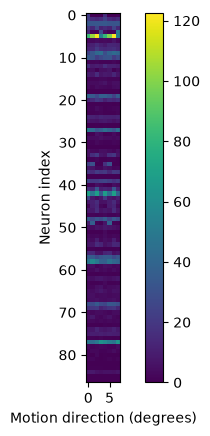

In [18]:
plt.imshow(tuning_matrix)
plt.xlabel("Motion direction (degrees)")
plt.ylabel("Neuron index")
plt.colorbar()
plt.show()

In [19]:
normalized_tuning = np.empty((87, 8))

for i in range(87):
    row_max = np.max(tuning_matrix[i])
    for direction in range(len(np.unique(Y))):
        if row_max != 0:
            normalized_tuning[i][direction] = (tuning_matrix[i][direction])/row_max
        else:
            normalized_tuning[i][direction] = (tuning_matrix[i][direction])

In [20]:
print(normalized_tuning.shape)
print(np.min(normalized_tuning))
print(np.max(normalized_tuning))
print(np.all(np.isfinite(normalized_tuning)))

(87, 8)
0.0
1.0
True


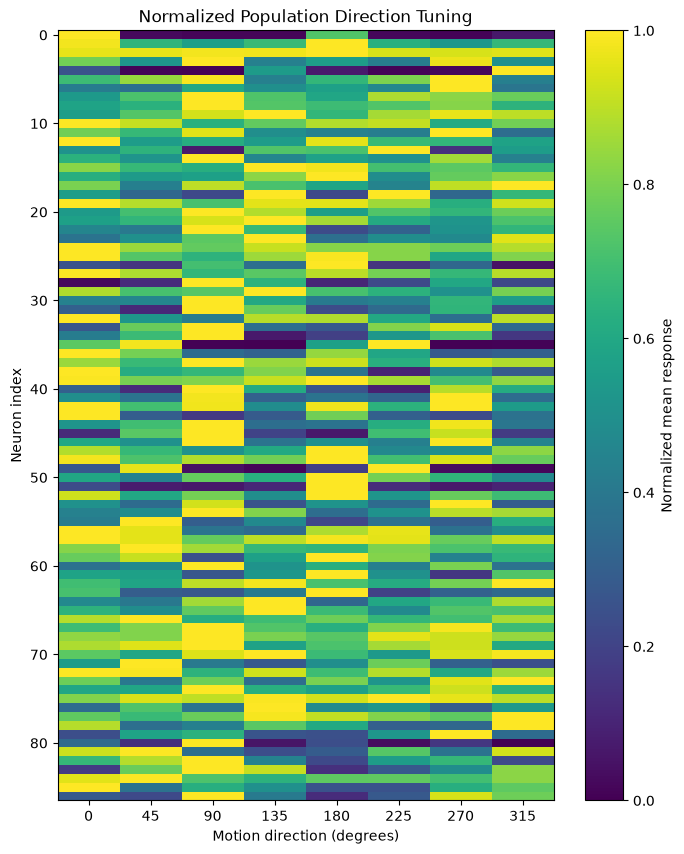

In [21]:
plt.figure(figsize=(8, 10))

plt.imshow(normalized_tuning, aspect='auto', vmin=0, vmax=1)

plt.xticks(range(len(directions)), directions.astype(int))

plt.xlabel("Motion direction (degrees)")
plt.ylabel("Neuron index")
plt.title("Normalized Population Direction Tuning")

plt.colorbar(label="Normalized mean response")

plt.show()

In [22]:
preferred_directions = []
for i in range(87):
    pref_dir_per_neur = np.argmax(normalized_tuning[i])
    preferred_directions.append(directions[pref_dir_per_neur])

In [23]:
value, counts = np.unique(preferred_directions, return_counts=True)
print(value, counts)

[  0.  45.  90. 135. 180. 225. 270. 315.] [15  6 26 10 13  4  7  6]


In [24]:
how_many_0_maxs = 0

for i in range(87):
    row_max = np.max(tuning_matrix[i])

    if row_max == 0:
        how_many_0_maxs += 1

print(how_many_0_maxs)

0


In [25]:
tuning_matrix

array([[2.19466667e+01, 5.73333333e-01, 2.66666667e-01, 3.20000000e-01,
        1.60266667e+01, 3.60000000e-01, 2.40000000e-01, 1.38666667e+00],
       [2.26000000e+01, 1.50266667e+01, 1.29466667e+01, 1.55866667e+01,
        2.30133333e+01, 1.46133333e+01, 1.21600000e+01, 1.53066667e+01],
       [3.26133333e+01, 3.27333333e+01, 3.32666667e+01, 3.31733333e+01,
        3.39066667e+01, 3.19066667e+01, 3.18666667e+01, 3.23066667e+01],
       [2.04400000e+01, 1.35466667e+01, 2.59733333e+01, 1.13600000e+01,
        1.44266667e+01, 1.10400000e+01, 2.52133333e+01, 1.31066667e+01],
       [1.31466667e+01, 5.33333333e-01, 3.06666667e-01, 2.81600000e+01,
        3.62666667e+00, 4.13333333e-01, 1.18666667e+00, 5.11866667e+01],
       [8.38666667e+01, 1.03826667e+02, 1.21093333e+02, 5.32266667e+01,
        8.12000000e+01, 9.82000000e+01, 1.22586667e+02, 5.30000000e+01],
       [2.76000000e+00, 2.42666667e+00, 3.94666667e+00, 3.26666667e+00,
        3.72000000e+00, 3.05333333e+00, 6.54666667e+00, 2.

In [26]:
response_ranges = []
for i in tuning_matrix:
    response_ranges.append((np.max(i)-np.min(i)))

response_range_mean = np.mean(response_ranges)
response_range_median = np.median(response_ranges)
response_range_min = np.min(response_ranges)
response_range_max = np.max(response_ranges)
print(response_range_min, response_range_max, response_range_mean, response_range_median)

0.08 69.58666666666667 8.262375478927202 3.84


In [27]:
norm_response_ranges = []
for i in normalized_tuning:
    norm_response_ranges.append((np.max(i)-np.min(i)))

norm_response_range_mean = np.mean(norm_response_ranges)
norm_response_range_median = np.median(norm_response_ranges)
norm_response_range_min = np.min(norm_response_ranges)
norm_response_range_max = np.max(norm_response_ranges)
print(norm_response_range_min, norm_response_range_max, norm_response_range_mean, norm_response_range_median)


0.06016515926071564 1.0 0.6109809737527896 0.6268656716417911


In [28]:
mean_spike_count = np.mean(X, axis=0)

In [29]:
print(len(mean_spike_count))
print(len(response_ranges))
print(len(norm_response_ranges))

87
87
87


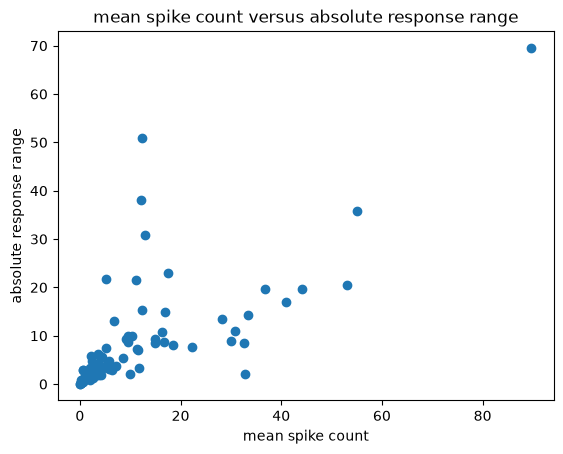

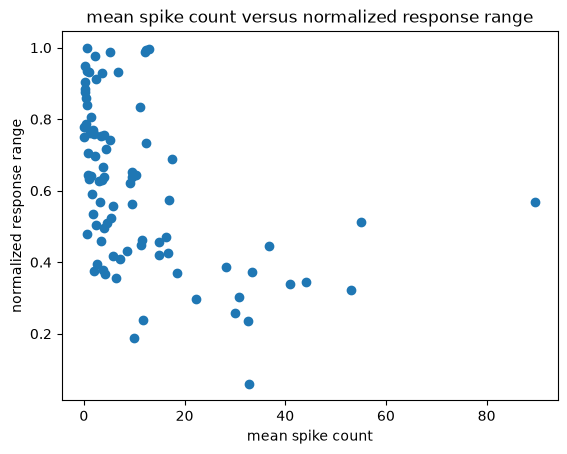

In [30]:
plt.scatter(mean_spike_count, response_ranges)
plt.title("mean spike count versus absolute response range")
plt.xlabel("mean spike count")
plt.ylabel("absolute response range")
plt.show()

plt.scatter(mean_spike_count, norm_response_ranges)
plt.title("mean spike count versus normalized response range")
plt.xlabel("mean spike count")
plt.ylabel("normalized response range")
plt.show()

In [31]:
abs_correlation = stats.pearsonr(mean_spike_count, response_ranges)
norm_correlation = stats.pearsonr(mean_spike_count, norm_response_ranges)
print(abs_correlation, norm_correlation)

PearsonRResult(statistic=np.float64(0.7182318086609094), pvalue=np.float64(4.858518247250366e-15)) PearsonRResult(statistic=np.float64(-0.45446405403640006), pvalue=np.float64(9.792026231544078e-06))
